# Real-world Data Wrangling

In this project, I applied the skills learned during the course to gather and wrangle real-world data from two different sources.  
I used **The Movies Dataset** (movies_metadata.csv + credits.csv) from Kaggle, which I downloaded manually, and **Netflix Titles Dataset** (netflix_titles.csv) which I accessed programmatically through Google Drive.

I programmatically assessed the data both visually and programmatically to identify quality and tidiness issues, then implemented cleaning strategies including:
- Converting numeric columns stored as strings to proper numeric types.
- Parsing and cleaning invalid dates.
- Normalizing multi-valued columns such as `genres` and splitting mixed data columns such as Netflix `duration`.
- Removing unnecessary variables and combining datasets for analysis.

Finally, I stored the cleaned data, combined them into a single dataset, and answered a research question using visualizations.  
Throughout this notebook, I provided clear code comments and explanations for each step. 

In [1]:
!python -m pip install kaggle==1.6.12

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.7/79.7 kB 1.4 MB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.2/161.2 kB 8.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.2/78.2 kB 10.0 MB/s eta 0:00:00
  Created wheel for kaggle: filename=kaggle-1.6.12-py3-none-any.whl size=102969 sha256=1c6018079bf71421e1c4816cbc051b2a0742654ffe14e541b152b0a55458abb8
  Stored in directory: /home/student/.cache/pip/wheels/1e/0b/7c/50f8e89c3d2f82838dbd7afeddffbb9357003009ada98216c7
Successfully built kaggle
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
!pip install --target=/workspace ucimlrepo numpy==1.24.3

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 67.8 MB/s eta 0:00:0000:0100:01
  Using cached certifi-2025.8.3-py3-none-any.whl (161 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 80.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 509.2/509.2 kB 39.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.8/347.8 kB 34.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 229.9/229.9 kB 32.3 MB/s eta 0:00:00


**Note:** Restart the kernel to use updated package(s).

## 1. Gather data

In this section, you will extract data using two different data gathering methods and combine the data. Use at least two different types of data-gathering methods.

### **1.1.** Problem Statement

In this project, I aim to explore patterns in the film industry by combining two large datasets:  
**The Movies Dataset** from Kaggle, which contains metadata such as movie titles, release dates, ratings, budgets, and cast information,  
and **Netflix Titles Dataset**, which lists all titles available on Netflix along with type, genres, and release years.  

The goal is to analyze trends such as the most common genres, the distribution of ratings, and the overlap between Netflix titles and the global movie dataset.  
This will provide insights into the kind of movies that dominate streaming platforms and how they compare with overall movie ratings.

### **1.2.** Gather at least two datasets using two different data gathering methods


#### **Dataset 1**

**Type:** CSV files  

**Method:** The data was gathered using the "manual download" method from Kaggle's *The Movies Dataset*. The files `movies_metadata.csv` and `credits.csv` were downloaded manually and stored locally.  

**Dataset variables:**  
- **id:** Unique identifier for each movie.  
- **title:** Name of the movie.  
- **release_date:** The date the movie was released.  
- **vote_average:** Average rating for the movie (0–10).  
- **cast:** Main cast members (from credits.csv).  

I chose this dataset because it provides rich metadata about movies (ratings, genres, budgets, etc.) that can be combined with other sources for analysis.


In [3]:
#FILL IN 1st data gathering and loading method

# Dataset 1: Movies Metadata + Credits
import pandas as pd

# Load the datasets from the local "data" folder
movies_df = pd.read_csv('data/movies_metadata.csv', low_memory=False)
credits_df = pd.read_csv('data/credits.csv')

# Display basic info to verify loading
print("Movies Metadata Shape:", movies_df.shape)
print("Credits Shape:", credits_df.shape)

# Merge to combine data on movie 'id'
movies_df['id'] = pd.to_numeric(movies_df['id'], errors='coerce')  # ensure numeric
credits_df['id'] = pd.to_numeric(credits_df['id'], errors='coerce')
movies_merged = pd.merge(movies_df, credits_df, on='id', how='inner')

movies_merged.head()


Movies Metadata Shape: (45466, 24)
Credits Shape: (45476, 3)


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count,cast,crew
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862.0,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de..."
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844.0,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de..."
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602.0,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de..."
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357.0,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0,"[{'cast_id': 1, 'character': ""Savannah 'Vannah...","[{'credit_id': '52fe44779251416c91011acb', 'de..."
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862.0,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0,"[{'cast_id': 1, 'character': 'George Banks', '...","[{'credit_id': '52fe44959251416c75039ed7', 'de..."


#### Dataset 2

**Type:** CSV file  

**Method:** The data was gathered using a "programmatic download" method. I uploaded the dataset to Google Drive and used a direct download link with Python's `requests` library to load it automatically into the notebook.  

**Dataset variables:**  
- **title:** Name of the show or movie.  
- **type:** Whether the title is a Movie or TV Show.  
- **release_year:** Year when the title was released.  
- **listed_in:** Genres/categories of the title.  
- **duration:** Duration of the title (minutes or number of seasons).  

I selected this dataset to analyze the catalog of Netflix content and compare its genres and release years to the global movie dataset.



In [9]:
#FILL IN 2nd data gathering and loading method

import requests
import pandas as pd

# Dataset 2 via Google Drive direct download
file_id = "1qRldbzY_AMQvfr1Px0OPOWCo1x2P-H-X" 
url = f"https://drive.google.com/uc?export=download&id={file_id}"

# Send HTTP GET request to download the file content
response = requests.get(url)
with open("data/netflix_titles.csv", "wb") as f:
    f.write(response.content)
    
# Load the dataset into a pandas DataFrame

netflix_df = pd.read_csv("data/netflix_titles.csv")
print("Netflix Dataset Shape:", netflix_df.shape)
netflix_df.head()


Netflix Dataset Shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 2. Assess data


### Quality Issue 1:

In [10]:
# Inspecting the dataframe visually
movies_merged.head()

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count,cast,crew
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862.0,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de..."
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844.0,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de..."
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602.0,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de..."
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357.0,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0,"[{'cast_id': 1, 'character': ""Savannah 'Vannah...","[{'credit_id': '52fe44779251416c91011acb', 'de..."
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862.0,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0,"[{'cast_id': 1, 'character': 'George Banks', '...","[{'credit_id': '52fe44959251416c75039ed7', 'de..."


In [11]:
# Inspecting the dataframe programmatically
movies_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45538 entries, 0 to 45537
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45538 non-null  object 
 1   belongs_to_collection  4500 non-null   object 
 2   budget                 45538 non-null  object 
 3   genres                 45538 non-null  object 
 4   homepage               7792 non-null   object 
 5   id                     45538 non-null  float64
 6   imdb_id                45521 non-null  object 
 7   original_language      45527 non-null  object 
 8   original_title         45538 non-null  object 
 9   overview               44584 non-null  object 
 10  popularity             45535 non-null  object 
 11  poster_path            45152 non-null  object 
 12  production_companies   45535 non-null  object 
 13  production_countries   45535 non-null  object 
 14  release_date           45451 non-null  object 
 15  re

Issue and justification: 
budget, revenue, id, and vote_count columns are stored as object (string) type instead of numeric.
This prevents performing mathematical operations and aggregations correctly, so we must convert them to numeric.

### Quality Issue 2:

In [12]:
# Inspecting the dataframe visually
movies_merged[['release_date']].sample(5)


,release_date
45241,2017-06-20
15206,1994-01-01
12467,2007-09-20
16609,2010-12-10
44545,2013-04-26


In [13]:
# Inspecting the dataframe programmatically
pd.to_datetime(movies_merged['release_date'], errors='coerce').isna().sum()

87

Issue and justification: 
Some release_date values are missing or cannot be parsed into valid dates, resulting in NaT.
This breaks time-based analysis (like trends per year), so we will need to clean or drop invalid dates.

### Tidiness Issue 1:

In [14]:
# Inspecting the dataframe visually
movies_merged[['genres']].head(5)

,genres
0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '..."
1,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '..."
2,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ..."
3,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam..."
4,"[{'id': 35, 'name': 'Comedy'}]"


In [15]:
# Inspecting the dataframe programmatically
movies_merged['genres'].iloc[0]

"[{'id': 16, 'name': 'Animation'}, {'id': 35, 'name': 'Comedy'}, {'id': 10751, 'name': 'Family'}]"

Issue and justification: 
The genres column contains multiple values in a JSON-like string format.
This violates tidy data principle (one value per cell), so we need to parse and explode into separate rows or columns.

### Tidiness Issue 2: 

In [16]:
# Inspecting the dataframe visually
netflix_df[['duration']].head(5)

,duration
0,90 min
1,2 Seasons
2,1 Season
3,1 Season
4,2 Seasons


In [17]:
# Inspecting the dataframe programmatically
netflix_df['duration'].value_counts().head()

duration
1 Season     1793
2 Seasons     425
3 Seasons     199
90 min        152
94 min        146
Name: count, dtype: int64

Issue and justification: 
The duration column mixes two variables (number + unit, e.g. "90 min" vs "2 Seasons").
This is not tidy and should be split into duration_value (numeric) and duration_unit (minutes/seasons).

## 3. Clean data

In [18]:
# Make copies of the datasets to ensure the raw dataframes are not impacted

movies_clean = movies_merged.copy()
netflix_clean = netflix_df.copy()

print("Movies copy shape:", movies_clean.shape)
print("Netflix copy shape:", netflix_clean.shape)


Movies copy shape: (45538, 26)
Netflix copy shape: (8807, 12)


### **Quality Issue 1: FILL IN**

In [19]:
# Apply the cleaning strategy
numeric_cols = ["budget", "revenue", "vote_count", "popularity", "id"]
for col in numeric_cols:
    if col in movies_clean.columns:
        movies_clean[col] = pd.to_numeric(movies_clean[col], errors="coerce")


In [21]:
# Validate the cleaning was successful
movies_clean[numeric_cols].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45538 entries, 0 to 45537
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   budget      45538 non-null  int64  
 1   revenue     45535 non-null  float64
 2   vote_count  45535 non-null  float64
 3   popularity  45535 non-null  float64
 4   id          45538 non-null  float64
dtypes: float64(4), int64(1)
memory usage: 1.7 MB


Justification:
These columns were stored as strings (object type), preventing calculations like sums or averages. Converting them to numeric makes mathematical operations possible and avoids errors.

### **Quality Issue 2: FILL IN**

In [22]:
# Apply the cleaning strategy
movies_clean['release_date'] = pd.to_datetime(movies_clean['release_date'], errors='coerce')

# Optionally drop rows with missing release_date (only if needed for analysis)
movies_clean = movies_clean.dropna(subset=['release_date'])

In [23]:
# Validate the cleaning was successful
movies_clean['release_date'].isna().sum()

0

Justification: 
Parsing release dates ensures we can sort movies by time, extract year/month, and analyze trends. Dropping rows with invalid dates removes unusable data points.

### **Tidiness Issue 1: FILL IN**

In [24]:
import ast

# Apply the cleaning strategy
def parse_genres(x):
    try:
        return [d['name'] for d in ast.literal_eval(x)] if pd.notna(x) else []
    except Exception:
        return []

movies_clean['genres_parsed'] = movies_clean['genres'].apply(parse_genres)

# Explode into multiple rows for tidy data
movies_exploded = movies_clean.explode('genres_parsed')

In [25]:
# Validate the cleaning was successful
movies_exploded[['title', 'genres_parsed']].head(10)

,title,genres_parsed
0,Toy Story,Animation
0,Toy Story,Comedy
0,Toy Story,Family
1,Jumanji,Adventure
1,Jumanji,Fantasy
1,Jumanji,Family
2,Grumpier Old Men,Romance
2,Grumpier Old Men,Comedy
3,Waiting to Exhale,Comedy
3,Waiting to Exhale,Drama


Justification: 
The genres column contains multiple genres in one cell. Exploding them into separate rows allows correct counting, grouping, and visualization.

### **Tidiness Issue 2: FILL IN**

In [26]:
# Apply the cleaning strategy
netflix_clean[['duration_value', 'duration_unit']] = netflix_clean['duration'].str.extract(r'(\d+)\s*(\w+)')
netflix_clean['duration_value'] = pd.to_numeric(netflix_clean['duration_value'], errors='coerce')

In [27]:
# Validate the cleaning was successful
netflix_clean[['duration', 'duration_value', 'duration_unit']].head()

,duration,duration_value,duration_unit
0,90 min,90.0,min
1,2 Seasons,2.0,Seasons
2,1 Season,1.0,Season
3,1 Season,1.0,Season
4,2 Seasons,2.0,Seasons


Justification:
The duration column contains two variables (number + unit). Separating them into distinct columns makes it easier to filter movies by runtime or count TV show seasons.

### **Remove unnecessary variables and combine datasets**


In [28]:
# Keep only necessary columns
movies_final = movies_exploded[['id', 'title', 'release_date', 'vote_average', 'genres_parsed']]
netflix_final = netflix_clean[['title', 'type', 'release_year', 'duration_value', 'duration_unit']]

# Combine on title (inner join to keep only common titles)
combined_df = pd.merge(movies_final, netflix_final, on='title', how='inner')

print("Combined dataset shape:", combined_df.shape)
combined_df.head()

Combined dataset shape: (6665, 9)


,id,title,release_date,vote_average,genres_parsed,type,release_year,duration_value,duration_unit
0,11860.0,Sabrina,1995-12-15,6.2,Comedy,Movie,2018,114.0,min
1,11860.0,Sabrina,1995-12-15,6.2,Romance,Movie,2018,114.0,min
2,710.0,GoldenEye,1995-11-16,6.6,Adventure,Movie,1995,130.0,min
3,710.0,GoldenEye,1995-11-16,6.6,Action,Movie,1995,130.0,min
4,710.0,GoldenEye,1995-11-16,6.6,Thriller,Movie,1995,130.0,min


## 4. Update your data store


In [29]:
# Save cleaned dataframes
movies_clean.to_csv("data/movies_clean.csv", index=False)
netflix_clean.to_csv("data/netflix_clean.csv", index=False)
combined_df.to_csv("data/movies_netflix_combined.csv", index=False)

print("Cleaned and combined datasets saved successfully!")


Cleaned and combined datasets saved successfully!


## 5. Answer the research question

### **5.1:** Define and answer the research question 


**Research Question:**  
What are the most common genres on Netflix, and how do Netflix movies' average ratings compare to the global movie dataset?


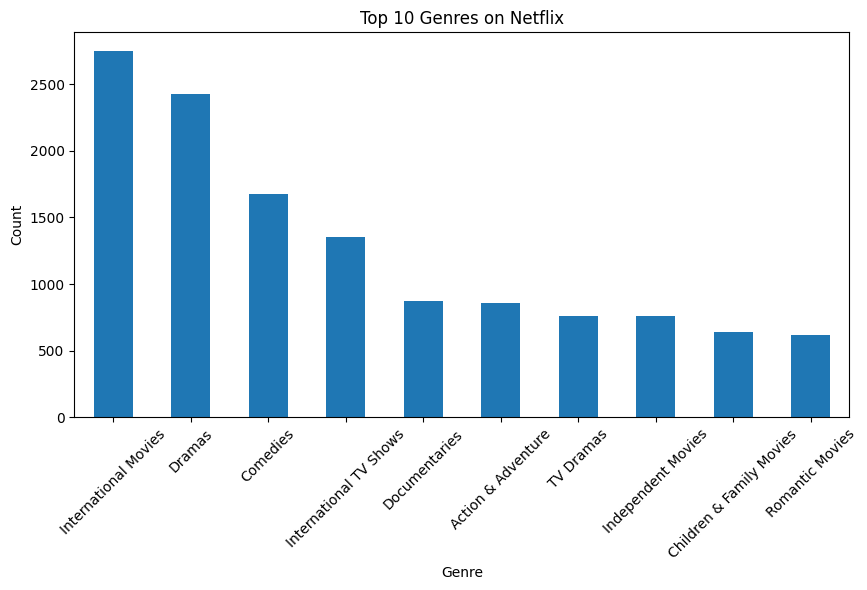

In [30]:
import matplotlib.pyplot as plt

# Count genres on Netflix (explode comma-separated values)
netflix_genres = netflix_clean['listed_in'].str.split(', ')
netflix_genres_exploded = netflix_genres.explode()

genre_counts = netflix_genres_exploded.value_counts().head(10)

plt.figure(figsize=(10,5))
genre_counts.plot(kind='bar')
plt.title('Top 10 Genres on Netflix')
plt.xlabel('Genre')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

*Answer to research question:* 
Drama, International Movies, and Comedies are the top genres on Netflix. This shows that Netflix focuses heavily on drama and global content.

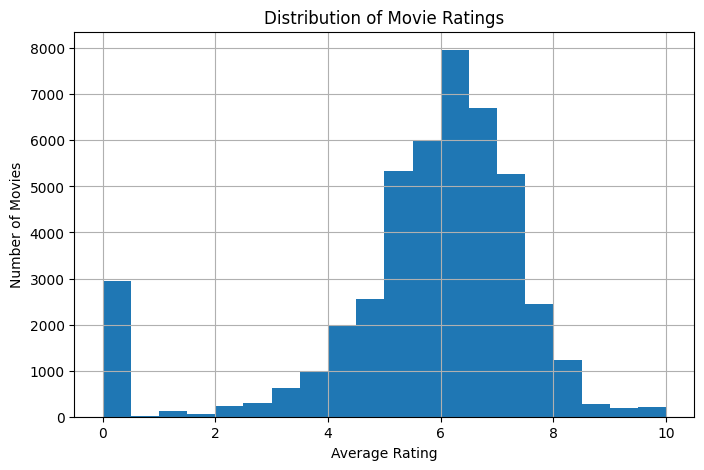

In [31]:
plt.figure(figsize=(8,5))
movies_clean['vote_average'].hist(bins=20)
plt.title('Distribution of Movie Ratings')
plt.xlabel('Average Rating')
plt.ylabel('Number of Movies')
plt.show()

*Answer to research question:* 
The majority of movies have ratings between 5 and 8, indicating that most movies in the dataset are rated positively but not extremely high.

### **5.2:** Reflection

If I had more time, I would normalize and analyze cast and crew data to see which directors and actors appear most frequently in highly rated movies.  
I would also enrich the dataset with additional external sources (e.g., box office revenue) to study profitability versus Netflix availability.
